# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abcreativeakshay/flyrank-ml-internship-starter/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

Everything in this dataset is heavy-tailed, and that one fact drives every method
choice below. Impressions per page over 90 days: **mean 5,200, median 731, p99
73,506, max 517,715** — the mean is 7× the median, so "average page" statistics
mostly describe a few giants. Clicks are starker: **median 1**. Search volume:
median 10, max 74,000. So in every test I compare **grouped declining rates with
visible n's** (never raw correlations on raw values), and I weight rates by their
denominators where rates are averaged.

Three traps I found while looking, before any test:

- **Per-row rates ≠ true rates.** Mean of per-page CTR is 0.51%; the real
  volume-weighted CTR (all clicks / all impressions) is 0.31%.
- **`position_tier = top_3` is two populations.** 1,116 rows have a measured
  position ≤ 3 (median 53 impressions/90d — tiny denominators, where one click
  moves CTR by ~2 points). The other 1,205 rows are `avg_position = 0` — *no
  position data at all* — with median 1 impression. I never read this tier without
  splitting it.
- **Update age is bimodal in practice:** `days_since_last_update` has median 20
  but p90 of 104 — most pages sit in a recently-updated band (0–30 days, 20,480
  rows) or a 91–180-day band (9,171 rows), with very little in between or beyond.
  The "very stale page" is rare in this slice (only 174 pages at 181+ days).


Loaded: data/raw/content_refresh_anonymized.csv | shape: (30000, 44)


                          mean  median      p90      p99       max
impressions_90d         5200.4   731.0  12136.4  73505.8  517715.0
clicks_90d                16.1     1.0     32.0    253.0    4178.0
sessions_90d              37.1     7.0     88.0    451.0    4345.0
search_volume            158.9    10.0    110.0   2900.0   74000.0
word_count              3107.8  2877.0   5327.0   7292.0    9546.0
ctr                        0.5     0.1      0.6      8.3     100.0
content_age_days         256.2   236.0    463.0    537.0     564.0
days_since_last_update    46.1    20.0    104.0    106.0     373.0


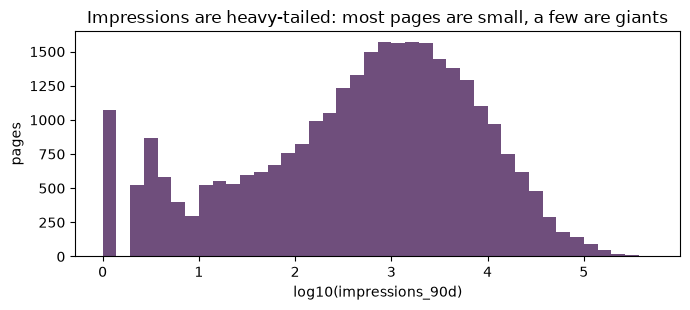


top_3 rows: 2321 | measured (avg_position>0): 1116 median impressions: 53.0 | no-data (avg_position==0): 1205 median impressions: 1.0
mean of per-row ctr (%): 0.51 | weighted CTR (%): 0.31


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

# Find the repo root by walking up from wherever this notebook was opened.
ROOT = Path.cwd()
while not (ROOT / "data/raw/content_refresh_anonymized.csv").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

RAW = ROOT / "data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(RAW)
print("Loaded:", RAW.relative_to(ROOT), "| shape:", df.shape)

import matplotlib.pyplot as plt

df["is_declining_label"] = (df["trend_direction"] == "down").astype(int)

# --- Heavy tails, in one table ---
cols = ["impressions_90d", "clicks_90d", "sessions_90d", "search_volume",
        "word_count", "ctr", "content_age_days", "days_since_last_update"]
summary = df[cols].describe(percentiles=[0.5, 0.9, 0.99]).T[["mean", "50%", "90%", "99%", "max"]]
summary.columns = ["mean", "median", "p90", "p99", "max"]
print(summary.round(1))

# --- The shape of the biggest tail ---
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(np.log10(df["impressions_90d"]), bins=40, color="#6F4E7C")
ax.set_xlabel("log10(impressions_90d)")
ax.set_ylabel("pages")
ax.set_title("Impressions are heavy-tailed: most pages are small, a few are giants")
plt.tight_layout()
plt.show()

# --- Trap check: position_tier top_3 is two populations ---
top3 = df[df["position_tier"] == "top_3"]
print()
print("top_3 rows:", len(top3),
      "| measured (avg_position>0):", int((top3["avg_position"] > 0).sum()),
      "median impressions:", top3.loc[top3["avg_position"] > 0, "impressions_90d"].median(),
      "| no-data (avg_position==0):", int((top3["avg_position"] == 0).sum()),
      "median impressions:", top3.loc[top3["avg_position"] == 0, "impressions_90d"].median())

# --- Rates need denominators ---
print("mean of per-row ctr (%):", round(df["ctr"].mean(), 2),
      "| weighted CTR (%):", round(100 * df["clicks_90d"].sum() / df["impressions_90d"].sum(), 2))


## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

**Test 1 — "Pages targeting higher-volume keywords decline less."**
Declining rate by `search_volume` bucket: 0 volume → **63.2%** (n=11,081);
1–100 → 52.4% (n=13,402); 101–1k → 50.1% (n=2,489); 1k–10k → 44.6% (n=493);
10k+ → 43.3% (n=67, below my sample floor — noted, not relied on).
**Verdict: CONFIRMED** — a clean monotone step down across every populated bucket.
Directional association only: demand context and decline move together in this
snapshot; this does not say low volume *causes* decline.

**Test 2 — "Older pages decline more."**
Declining rate by `age_tier`: 31–90 days → **66.9%** (n=492); 91–180 → 62.6%
(n=11,780); 181–365 → 51.5% (n=11,368); 365+ → **42.6%** (n=6,360).
**Verdict: OPPOSITE** — in this slice the oldest pages decline *least*. The
plausible reading is survivorship: pages that have lived 365+ days at measurable
volume are the durable ones. Either way, "old ⇒ refresh first" is not supported.

**Test 3 — "The longer since the last update, the more a page declines."**
Declining rate by time since update: 0–30 days → 51.1% (n=20,480); 31–90 → 58.9%
(n=175); 91–180 → 61.1% (n=9,171); 181+ → 47.1% (n=174).
**Verdict: MIXED** — the middle band is higher than the fresh band, but the most
stale band drops back down, and two of the four buckets sit near my ~50-row floor's
neighbourhood (n=175, n=174). Staleness alone is not a reliable decline signal in
this data.


In [2]:
def rate_table(frame, col, order=None):
    t = frame.groupby(col, observed=True)["is_declining_label"].agg(["mean", "count"])
    t.columns = ["declining_rate", "n"]
    t["declining_rate"] = (t["declining_rate"] * 100).round(1)
    return t.reindex(order) if order else t

print("TEST 1 - declining rate by search_volume bucket")
d = df.dropna(subset=["search_volume"]).copy()
d["sv_bucket"] = pd.cut(d["search_volume"], [-1, 0, 100, 1000, 10000, np.inf],
                        labels=["0", "1-100", "101-1k", "1k-10k", "10k+"])
print(rate_table(d, "sv_bucket"))
print()
print("TEST 2 - declining rate by age_tier")
print(rate_table(df, "age_tier", ["31-90", "91-180", "181-365", "365+"]))
print()
print("TEST 3 - declining rate by days_since_last_update bucket")
d3 = df.copy()
d3["upd_bucket"] = pd.cut(d3["days_since_last_update"], [-1, 30, 90, 180, np.inf],
                          labels=["0-30", "31-90", "91-180", "181+"])
print(rate_table(d3, "upd_bucket"))


TEST 1 - declining rate by search_volume bucket
           declining_rate      n
sv_bucket                       
0                    63.2  11081
1-100                52.4  13402
101-1k               50.1   2489
1k-10k               44.6    493
10k+                 43.3     67

TEST 2 - declining rate by age_tier
          declining_rate      n
age_tier                       
31-90               66.9    492
91-180              62.6  11780
181-365             51.5  11368
365+                42.6   6360

TEST 3 - declining rate by days_since_last_update bucket
            declining_rate      n
upd_bucket                       
0-30                  51.1  20480
31-90                 58.9    175
91-180                61.1   9171
181+                  47.1    174


## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

I tested the baseline rule **`low_ctr_visible_page`** (from the reference
baseline's reason codes): a page with `impressions_90d >= 500`, average position
1–20 and `ctr < 0.5%` gets flagged and routed to the action
`refresh_and_review_ctr`. The rule's working assumption: **among visible pages,
the low-CTR ones are disproportionately the declining ones** — that's what makes
"review the CTR" the right first action for them.

Measured on this slice: pages the rule fires on are declining at **62.7%**
(n=9,759), against **47.5%** (n=2,264) for other equally visible pages
(same impressions/position window, CTR ≥ 0.5%). The overall declining rate is
54.2%, so the rule's group sits clearly above base rate and its comparison group
below it. **Verdict: CONFIRMED — directionally.** The assumption holds as an
observed association, which supports using low CTR on a visible page as a
*review trigger*. One honest limit: CTR and trend are measured over the same 90
days, so this cannot show that fixing CTR would reverse a decline — only that
the flag points at the right pages.

Two neighbouring rules, checked in the same cell, fare worse — worth recording:
`page_one_decay_risk` (page-1 position, age ≥ 180 days) comes out **OPPOSITE**
(51.8% declining, n=7,076, vs 61.7% for younger page-1 pages — consistent with
test 2's survivorship pattern), and `stale_visible_page` fires only **17 times**
in this slice, so no verdict is possible here — below the sample floor, however
suggestive its 94.1% looks.


In [3]:
# --- The flag under test: low_ctr_visible_page ---
visible = (df["impressions_90d"] >= 500) & (df["avg_position"] > 0) & (df["avg_position"] <= 20)
flagged = visible & (df["ctr"] < 0.5)
print("low_ctr_visible_page fires on:", int(flagged.sum()), "pages")
print("  declining rate, flagged:            ", round(df.loc[flagged, "is_declining_label"].mean() * 100, 1), "%")
print("  declining rate, visible, not flagged:", round(df.loc[visible & ~flagged, "is_declining_label"].mean() * 100, 1),
      "%  (n =", int((visible & ~flagged).sum()), ")")
print("  declining rate, all pages:          ", round(df["is_declining_label"].mean() * 100, 1), "%")

# --- Neighbouring rules, same treatment ---
print()
p1 = (df["avg_position"] > 0) & (df["avg_position"] <= 10)
decay = p1 & (df["content_age_days"] >= 180)
print("page_one_decay_risk fires on:", int(decay.sum()),
      "| declining:", round(df.loc[decay, "is_declining_label"].mean() * 100, 1),
      "% vs younger page-1 pages:", round(df.loc[p1 & ~decay, "is_declining_label"].mean() * 100, 1), "%")
stale = (df["days_since_last_update"] >= 180) & (df["impressions_90d"] >= 500)
print("stale_visible_page fires on:", int(stale.sum()),
      "pages only -> below the sample floor, no verdict (declining:",
      round(df.loc[stale, "is_declining_label"].mean() * 100, 1), "% on n=17)")


low_ctr_visible_page fires on: 9759 pages
  declining rate, flagged:             62.7 %
  declining rate, visible, not flagged: 47.5 %  (n = 2264 )
  declining rate, all pages:           54.2 %

page_one_decay_risk fires on: 7076 | declining: 51.8 % vs younger page-1 pages: 61.7 %
stale_visible_page fires on: 17 pages only -> below the sample floor, no verdict (declining: 94.1 % on n=17)


## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

Prioritise refresh review where decline actually concentrates in this data:
visible pages with weak CTR, and pages whose keywords carry little or no search
volume — those signals held up under testing. Do **not** triage by age or by
time-since-update alone: the oldest pages here are the *least* likely to be
declining, and staleness points both ways. And before anyone quotes a position
tier, split the no-position rows out of `top_3` — as shipped, that tier is half
unmeasured pages.


In [4]:
verdicts = pd.DataFrame([
    ["T1 search volume: higher volume -> less decline", "CONFIRMED",
     "63.2% (vol 0) -> 44.6% (1k-10k), monotone"],
    ["T2 age: older pages decline more", "OPPOSITE",
     "66.9% (31-90d) -> 42.6% (365+d), monotone down"],
    ["T3 staleness: longer since update -> more decline", "MIXED",
     "51.1% fresh, 61.1% at 91-180d, 47.1% at 181+ (small n)"],
    ["Flag low_ctr_visible_page -> refresh_and_review_ctr", "CONFIRMED (directional)",
     "62.7% declining flagged vs 47.5% visible peers"],
    ["Flag page_one_decay_risk", "OPPOSITE",
     "51.8% (old page-1) vs 61.7% (young page-1)"],
    ["Flag stale_visible_page", "INSUFFICIENT DATA",
     "fires 17 times in this slice - below the sample floor"],
], columns=["test", "verdict", "key numbers"])
print(verdicts.to_string(index=False))


                                               test                 verdict                                            key numbers
    T1 search volume: higher volume -> less decline               CONFIRMED              63.2% (vol 0) -> 44.6% (1k-10k), monotone
                   T2 age: older pages decline more                OPPOSITE         66.9% (31-90d) -> 42.6% (365+d), monotone down
  T3 staleness: longer since update -> more decline                   MIXED 51.1% fresh, 61.1% at 91-180d, 47.1% at 181+ (small n)
Flag low_ctr_visible_page -> refresh_and_review_ctr CONFIRMED (directional)         62.7% declining flagged vs 47.5% visible peers
                           Flag page_one_decay_risk                OPPOSITE             51.8% (old page-1) vs 61.7% (young page-1)
                            Flag stale_visible_page       INSUFFICIENT DATA  fires 17 times in this slice - below the sample floor


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.